<font size="+2" color="#2680EB">Additional results</font>



Done at the end of the notebook 

Author: <font color="#2680EB">Anna Quílez Rodríguez</font>

E-mail: <font color="#2680EB"> anna.quilez01@estudiant.upf.edu</font>

AI used: <font color="#2680EB">ChatGPT. I used artificial intelligence to help me understand the functions I wasn’t familiar with and to write some of the code.</font>

Date: <font color="#2680EB">18/11/2026</font>

In [17]:
import io
import random
import statistics
import secrets
import re
import gzip

# Natural language processing
import nltk

# Timer
from timeit import default_timer as timer

# 0. Dataset and how to iterate

In [18]:
# LEAVE THIS CODE AS-IS

INPUT_FILE = "odyssey.txt.gz"

In [19]:
# LEAVE THIS CODE AS-IS

POS_NOUN = 'NN'
POS_ADJECTIVE = 'JJ'
POS_VERB = 'VB'
POS_ADVERB = 'RB'
POS_DETERMINER = 'DT'

# Producer in Python that reads a file by words that are nouns
def read_by_parts_of_speech(filename, parts_of_speech, max_words=-1, report_every=-1, use_pos_prefix=True):
    
    # Default value for report_every
    if report_every < 0 and max_words > 0:
        report_every = int(max_words/5)
    
    # Open the input file
    with gzip.open(INPUT_FILE, "rt", encoding='utf8') as file:
        
        # Initialize counter of words to stop at max_words
        counter = 0
    
        # Iterate through lines in the file
        for line in file:
                                        
            if counter > max_words and max_words != -1:
                print(f"Stopping: read {counter} words")
                break
                
            for sentence in nltk.sent_tokenize(line):
                
                words = []
                if parts_of_speech is None or len(parts_of_speech) == 0:
                    words = nltk.word_tokenize(sentence)
                else:
                    tagged = nltk.pos_tag(nltk.word_tokenize(sentence))
                    if use_pos_prefix:
                        words = [part[0] for part in tagged if any(part[1].startswith(prefix) for prefix in parts_of_speech)]
                    else:
                        words = [part[0] for part in tagged if part[1] in parts_of_speech]

                for word in words:

                    # Ensure the word is alphabetic (no punctuation, no numbers), and has at least two characters
                    if re.match(r'^[a-zA-Z]{2,}$', word):
                    
                        counter += 1

                        # Report
                        if (report_every != -1) and (counter % report_every == 0):
                            if max_words == -1:
                                print(f"- Read {counter} words so far")
                            else:
                                print(f"- Read {counter}/{max_words} words so far")

                        # Produce the word in lowercase
                        yield word.lower()

        print(f"Stopping: end of the input file reached")

In [20]:
# LEAVE THIS CODE AS-IS,
# BUT if it takes more than 30 seconds to run, then reduce MAX_WORDS parameter below

# Maximum number of words to read, one pass should take less than 30 seconds in your computer
MAX_WORDS = 400000

# Parts of speech we will focus on
POS_SELECTED = [POS_NOUN, POS_ADJECTIVE, POS_VERB, POS_ADVERB, POS_DETERMINER]

# We use prefixes because there are many variants (e.g., NN is noun, NNS is singular noun, and so on)

print(f"Reading up to {MAX_WORDS} words from {INPUT_FILE}")
start = timer()
for word in read_by_parts_of_speech(INPUT_FILE, POS_SELECTED, max_words=MAX_WORDS, use_pos_prefix=True):
    # Prints 1/1000 of words
    if random.random() < 0.001:
        print("-- Current word '%s'" % (word)) 

end = timer()
print(f"Ellapsed time: {end-start:.2f} seconds")

Reading up to 400000 words from odyssey.txt.gz
-- Current word 'points'
-- Current word 'yea'
-- Current word 'some'
-- Current word 'had'
-- Current word 'odyssey'
-- Current word 'identical'
-- Current word 'dead'
-- Current word 'so'
-- Current word 'had'
-- Current word 'ajax'
-- Current word 'much'
-- Current word 'offer'
-- Current word 'seals'
-- Current word 'atreus'
-- Current word 'fought'
-- Current word 'calypso'
-- Current word 'back'
-- Current word 'think'
-- Current word 'the'
-- Current word 'scandalised'
-- Current word 'end'
-- Current word 'raised'
-- Current word 'ship'
-- Current word 'the'
-- Current word 'king'
-- Current word 'the'
-- Current word 'were'
-- Current word 'achaeans'
-- Current word 'all'
-- Current word 'loosed'
-- Current word 'sails'
-- Current word 'the'
-- Current word 'made'
-- Current word 'leading'
-- Current word 'an'
-- Current word 'else'
-- Current word 'kind'
-- Current word 'men'
-- Current word 'day'
-- Current word 'something'
-- C

# 1. Determine approximately the top-10 words

## 1.1. Implement reservoir sampling <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Implement add_to_reservoir**</font>

In [21]:
def add_to_reservoir(reservoir, item, max_reservoir_size):
    
    # YOUR ANSWER HERE
    # Add the item if there is still space in the reservoir
    if len(reservoir) < max_reservoir_size:
        reservoir.append(item)
    else:
        # Remove a random item before adding the new one
        random_index = random.randrange(len(reservoir))
        reservoir.pop(random_index) #drop the element in this position 
        reservoir.append(item) 
    assert len(reservoir) <= max_reservoir_size, "Implementation error, reservoir is larger than max_reservoir_size"

<font size="+1" color="#2680EB">**Implement reservoir_sampling**</font>

In [22]:
def reservoir_sampling(filename, parts_of_speech, reservoir_size, max_words=-1, report_every=-1, use_pos_prefix=True):
    reservoir = []

    # YOUR ANSWER HERE
    words_seen=0; 
    # AI: Implementation of the reservoir sampling algorithm.

    # Read the words from the input stream
    for word in read_by_parts_of_speech(filename, parts_of_speech, max_words, report_every, use_pos_prefix):

        words_seen += 1

        # Fill the reservoir with the first elements
        if len(reservoir) < reservoir_size:
            add_to_reservoir(reservoir, word, reservoir_size)

        else:
            # Calculate the probability of including the new word
            probability = reservoir_size / words_seen

            # Replace a random element with the new word
            if random.random() < probability:
                add_to_reservoir(reservoir, word, reservoir_size)

    return (words_seen, reservoir)

In [23]:
# LEAVE THIS CODE AS-IS

reservoir_size = 1500
(words_seen, reservoir) = reservoir_sampling(INPUT_FILE, [POS_NOUN, POS_ADJECTIVE, POS_VERB], reservoir_size, max_words=MAX_WORDS, use_pos_prefix=True)

print(f"Sampled {len(reservoir)} of {words_seen} words")

Stopping: end of the input file reached
Sampled 1500 of 56952 words


## 1.2. Estimate frequencies using reservoir sampling <font color="#2680EB">[30%]</font>

In [24]:
# LEAVE THIS CODE AS-IS

freq = {}
for item in reservoir:
    freq[item] = reservoir.count(item)

most_frequent_items = sorted([(frequency, word) for word, frequency in freq.items()], reverse=True)[:20]
for absolute_frequency, word in most_frequent_items:
    print("%d %s" % (absolute_frequency, word))

29 was
23 have
23 had
14 were
14 said
14 do
13 man
12 telemachus
11 ulysses
10 suitors
10 house
10 home
10 are
9 son
9 is
9 be
8 went
8 old
8 made
7 way


<font size="+1" color="#2680EB">**Print the top 30 most frequent words in the reservoir.** Include their relative frequencies, as percentages in relation to the number of words read.</font>

In [25]:
NUM_ITEMS = 30

# YOUR ANSWER HERE

# Count the occurrences of each word in the reservoir
freq = {}
for word in reservoir:
    freq[word] = reservoir.count(word)

# Calculate the relative frequency and sort the results
most_frequent_items = sorted([(frequency, word, frequency / len(reservoir) * 100)for word, frequency in freq.items()],reverse=True)[:NUM_ITEMS]

# Print the 30 most frequent words and their relative frequencies
for absolute_frequency, word, relative_frequency in most_frequent_items:
    print(f"{word}: {absolute_frequency} ({relative_frequency:.4f}%)")


was: 29 (1.9333%)
have: 23 (1.5333%)
had: 23 (1.5333%)
were: 14 (0.9333%)
said: 14 (0.9333%)
do: 14 (0.9333%)
man: 13 (0.8667%)
telemachus: 12 (0.8000%)
ulysses: 11 (0.7333%)
suitors: 10 (0.6667%)
house: 10 (0.6667%)
home: 10 (0.6667%)
are: 10 (0.6667%)
son: 9 (0.6000%)
is: 9 (0.6000%)
be: 9 (0.6000%)
went: 8 (0.5333%)
old: 8 (0.5333%)
made: 8 (0.5333%)
way: 7 (0.4667%)
ship: 7 (0.4667%)
men: 7 (0.4667%)
let: 7 (0.4667%)
give: 7 (0.4667%)
come: 7 (0.4667%)
take: 6 (0.4000%)
see: 6 (0.4000%)
others: 6 (0.4000%)
other: 6 (0.4000%)
left: 6 (0.4000%)


In [26]:
# LEAVE AS_IS

POS_PROPER_NOUN = "NNP"

def word_count(input_filename, pos=[]):

    # The instructor used co-pilot to generate this function
    count = 0
    with gzip.open(input_filename, "rt", encoding='utf8') as file:
        for line in file:
            if pos:
                for sentence in nltk.sent_tokenize(line):
                    tagged = nltk.pos_tag(nltk.word_tokenize(sentence))
                    count += len([word for word, tag in tagged if tag in pos])
            else:
                count += len(nltk.word_tokenize(line))
    return count

TOTAL_WORD_COUNT = word_count(INPUT_FILE)
TOTAL_PROPER_NOUN_COUNT = word_count(INPUT_FILE, pos=[POS_PROPER_NOUN])

print(f"The file contains {TOTAL_WORD_COUNT} words, of which {TOTAL_PROPER_NOUN_COUNT} are proper nouns")

The file contains 149544 words, of which 5947 are proper nouns


<font size="+1" color="#2680EB">**Print the top 10 proper nouns in the dataset and their estimated frequency.** Try with various reservoir sizes.</font>

In [27]:
NUM_ITEMS = 10

def print_top_proper_nouns(input_filename, reservoir_size, max_words=-1, report_every=-1):

    (words_seen, reservoir) = reservoir_sampling(input_filename, [POS_PROPER_NOUN], reservoir_size, max_words=max_words, report_every=report_every, use_pos_prefix=False)

    # YOUR ANSWER HERE
    # Count the occurrences of each proper noun
    freq = {}
    for word in reservoir:
        freq[word] = reservoir.count(word)

    # Estimate the frequency in the complete dataset
    estimated_frequencies = [(frequency * words_seen / len(reservoir), word)for word, frequency in freq.items()]
    # Sort the estimated frequencies and select the top 10
    top_items = sorted(estimated_frequencies, reverse=True)[:NUM_ITEMS]

    for estimated_frequency, word in top_items:
        print(f"{word}: approximately {estimated_frequency:.0f} occurrences")

#Test with various reservoir sizes
#for size in [10, 50, 100, 150, 200, 500, 1000]:
    #print_top_proper_nouns(INPUT_FILE, size)

print_top_proper_nouns(INPUT_FILE, 1000)

Stopping: end of the input file reached
telemachus: approximately 246 occurrences
ulysses: approximately 204 occurrences
jove: approximately 181 occurrences
minerva: approximately 130 occurrences
penelope: approximately 125 occurrences
ithaca: approximately 111 occurrences
eumaeus: approximately 88 occurrences
troy: approximately 79 occurrences
neptune: approximately 79 occurrences
alcinous: approximately 79 occurrences


<font size="+1" color="#2680EB">**Answer the questions below** regarding the variations observed with various reservoir sizes.</font>

**Answer.**

Which reservoir sizes did you test?

* I tested the following reservoir sizes: 10, 50, 100, 150, 200, 500 and 1000.

At which reservoir size do the top-3 proper nouns estabilize across runs? What are those proper nouns? Who they correspond to in the novel?

* The top 3 seem to become more stable from a reservoir size of 500. The three most frequent proper nouns are Telemachus, Ulysses and Jove. Their order and estimated frequencies change slightly between runs, but the same three names appear in the larger samples.

  * Telemachus: The son of Ulysses.
  * Ulysses: The main character of the novel and the king of Ithaca.
  * Jove: Another name for Jupiter (Zeus), the king of the gods.

# 2. Determine approximately the distinct number of words <font color="#2680EB">[50%]</font>

In [13]:
# LEAVE THIS CODE AS-IS

def count_trailing_zeroes(number):
    count = 0
    while number & 1 == 0:
        count += 1
        number = number >> 1
    return count

In [14]:
# LEAVE THIS CODE AS-IS

def random_hash_function():
    # We use a cryptographically safe generator for the salt of our hash function
    salt = secrets.token_bytes(32)
    return lambda string: hash(string + str(salt))

<font size="+1" color="#2680EB">**Implement a generator of estimates** that does a number of passes over the data.</font>

In [15]:

NUMBER_OF_PASSES = 5

estimates = []
start_time = timer()

for i in range(NUMBER_OF_PASSES):
    hasher = random_hash_function()

    # YOUR ANSWER HERE
    max_trailing_zeroes = 0

    # Read all the words in the stream
    for word in read_by_parts_of_speech(INPUT_FILE, [], max_words=MAX_WORDS):
        hash_value = hasher(word)

        # Count the trailing zeroes of the hash
        if hash_value != 0:
            trailing_zeroes = count_trailing_zeroes(abs(hash_value))
            max_trailing_zeroes = max(max_trailing_zeroes, trailing_zeroes)

    # Estimate the number of distinct words
    estimation = 2 ** max_trailing_zeroes

    estimates.append(estimation)
    print(f"Estimate on pass {i+1}: {estimation} distinct words")

elapsed_time = timer() - start_time
print(f"Total time: {elapsed_time:.2f} seconds")


- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 1: 4096 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 2: 2048 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 3: 8192 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 4: 65536 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 5: 16384 distinct words
Total time: 2.73 seconds


In [16]:
# Leave this code as-is

print("* Average of estimates: %.1f" % statistics.mean(estimates))
print("* Median  of estimates: %.1f" % statistics.median(estimates))

* Average of estimates: 19251.2
* Median  of estimates: 8192.0


<font size="+1" color="#2680EB">**Answer the questions below** regarding the probabilistic measurements you have done.</font>

**Answer.**

What was the maximum number of passes you did? How much time did it take?

* I performed 5 passes over the file. It took approximately 2.73 seconds.

Considering that the Odyssey actually has around 8,200 distinct words, how did the estimate based on **average** perform?

* The average estimate was 19,251.2 distinct words. This is much higher than the actual number of approximately 8,200 words, so the method overestimated the number of distinct words because the average is sensible to extrem values.

Considering that the Odyssey actually has around 8,200 distinct words, how did the estimate based on **median** perform?

* The median estimate was 8,192 distinct words. This is very close to the actual number of approximately 8,200 words, so it gave a very accurate estimate.

Can you comment on both estimates?

* The median gave a much better result than the average. This is because one of the estimates was much higher than the others, which increased the average. The median was less affected by this value. This shows that using the median can give a more reliable result when some estimates are very different from the others.


# DELIVER (individually)

Remember to read the section on "delivering your code" in the [course evaluation guidelines](https://github.com/chatox/data-mining-course/blob/master/upf/upf-evaluation.md).

Deliver this notebook, renamed as `PSxx_Unnnnnn_YourName.ipynb` where:
* *PSxx* is the practice number.
* *Unnnnnn* is your UPF id number.
* *YourName* is your name.

## Extra points available

For more learning and extra points, pick one of these activities:

(1) Plot the average and median estimate for runs 1 to X, for various values of X.

(2) Notice that the number of **distinct** words in a corpus, as a function of the **total** number of words in the corpus, follows an empirical law known as [Heap's Law](https://en.wikipedia.org/wiki/Heaps%27_law).

Plot the estimate of distinct words versus number of words read. For this, you need to try with various values of `max_word`. Please note that using probabilistic counting means a substantial amount of noise will be introduced and perhaps the Heap's law will not be clear in your plot.

**Note:** if you go for the extra points, add ``<font size="+2" color="#2680EB">Additional results</font>`` at the top of your notebook. 

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+2" color="#2680EB">Additional results</font>

In [32]:
import matplotlib.pyplot as plt

NUMBER_OF_PASSES = 30

estimates = []

for i in range(NUMBER_OF_PASSES):
    hasher = random_hash_function()

    # YOUR ANSWER HERE
    max_trailing_zeroes = 0

    # Read all the words in the stream
    for word in read_by_parts_of_speech(INPUT_FILE, [], max_words=MAX_WORDS):
        hash_value = hasher(word)

        # Count the trailing zeroes of the hash
        if hash_value != 0:
            trailing_zeroes = count_trailing_zeroes(abs(hash_value))
            max_trailing_zeroes = max(max_trailing_zeroes, trailing_zeroes)

    # Estimate the number of distinct words
    estimation = 2 ** max_trailing_zeroes

    estimates.append(estimation)
    print(f"Estimate on pass {i+1}: {estimation} distinct words")

average_estimates=[]
median_estimates=[]

for i in range(1, NUMBER_OF_PASSES+1):
    average_estimates.append(statistics.mean(estimates[:i]))
    median_estimates.append(statistics.median(estimates[:i]))


- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 1: 2048 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 2: 16384 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 3: 2048 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 4: 1024 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 5: 8192 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 6: 4096 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 7: 4096 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 8: 8192 distinct words
- Read 80000/400000 words so far
Stopping: end of the input file reached
Estimate on pass 9: 20

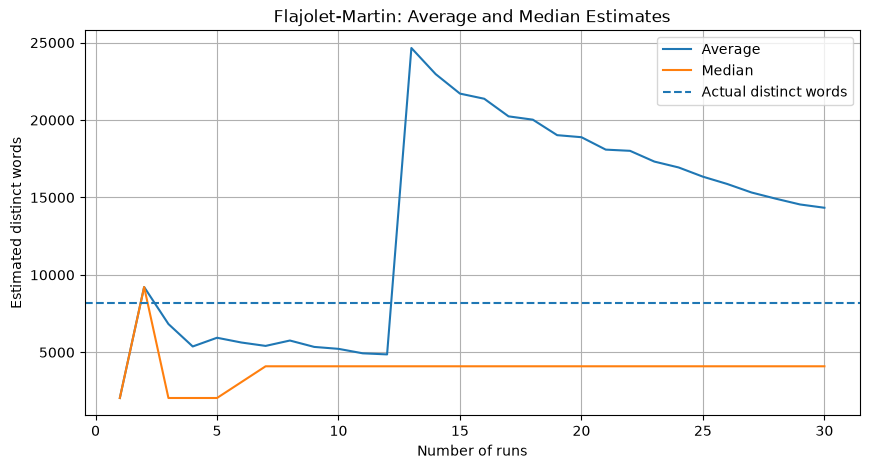

In [ ]:
#  To plot the results I used AI 

plt.figure(figsize=(10, 5))

plt.plot(range(1, NUMBER_OF_PASSES + 1), average_estimates, label="Average")
plt.plot(range(1, NUMBER_OF_PASSES + 1), median_estimates, label="Median")

plt.axhline(y=8200, linestyle="--", label="Actual distinct words")

plt.xlabel("Number of runs")
plt.ylabel("Estimated distinct words")
plt.title("Flajolet-Martin: Average and Median Estimates")
plt.legend()
plt.grid()
plt.show()

**Observations and conclusions:** The graph shows how the average and median estimates change over 30 passes. The average changes a lot, especially after pass 13, because one estimate is much higher than the others. After that, it starts to decrease.

The median is more stable because it is less affected by very high or low values. After 30 passes, the average is approximately 15,000 words and the median is 4,096 words.

Considering that The Odyssey has around 8,200 distinct words, the average is higher than the real value, while the median is lower. This shows that the results can change depending on the hash functions used.

<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that my answers were not written by an AI-enabled code assistant, and that except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>